# Diagnostics and robustness
Forecast diagnostics, overlay ablation, deflated Sharpe and parameter sensitivity.

In [1]:
import sys
sys.path.insert(0, '../code')
import pandas as pd
from kairos import config
P = config.PATHS
pd.read_csv(P.tables / 'regime_return_link.csv')

,Asset,Window,n,CorrStressNextRet,MeanRetStressed,MeanRetCalm,StressedMonths
0,BTC-USD,initial_window,48,-0.151107,-0.032730,0.105925,11
1,BTC-USD,after,83,0.185886,0.060300,0.006247,32
2,DBC,initial_window,48,-0.143095,0.002748,0.011810,39
3,DBC,after,187,0.172580,0.003883,0.000460,51
4,EFA,initial_window,48,-0.323734,-0.024214,0.015582,24
5,EFA,after,211,0.197683,0.015288,0.003461,69
6,ETH-USD,initial_window,48,0.042775,0.045349,0.040283,28
7,ETH-USD,after,46,0.318039,0.092260,-0.010276,9
8,GLD,initial_window,48,-0.029545,0.016643,0.020769,34
9,GLD,after,201,0.120127,0.005890,0.006439,59


In [2]:
pd.read_csv(P.tables / 'ic_diagnostics_summary.csv', index_col=0)

,MeanIC,MeanIC_equities,MeanR2OOS,AssetsPositiveIC,Assets
Variant,,,,,
as_specified,-0.010659,-0.064262,-0.064769,3,9
no_regime_features,-0.019944,-0.092900,-0.065607,4,9
no_stress_features,0.001522,-0.084324,-0.057991,5,9
longer_initial_window,-0.010659,-0.064262,-0.064769,3,9
no_regime_longer_window,-0.019944,-0.092900,-0.065607,4,9


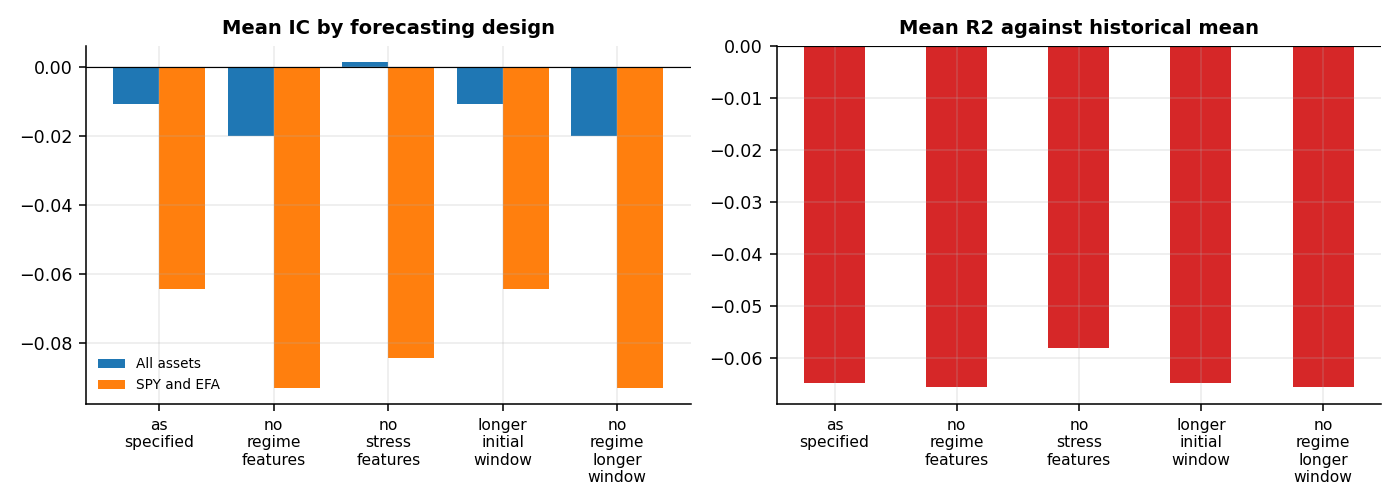

In [3]:
from IPython.display import Image
Image(str(P.figures / '12_ic_diagnostics.png'))

In [4]:
pd.read_csv(P.tables / 'deflated_sharpe.csv')

,strategy,Sharpe,BenchmarkSharpe,DSR,Trials
0,BL_ML_Regime,0.804914,0.067735,0.998307,5
1,BL_ML_Regime,0.804914,0.089431,0.997773,10
2,BL_ML_Regime_IC,0.859145,0.067735,0.999086,5
3,BL_ML_Regime_IC,0.859145,0.089431,0.998783,10
4,BL_ML_NoRegime,0.825081,0.067735,0.998677,5
5,BL_ML_NoRegime,0.825081,0.089431,0.998250,10


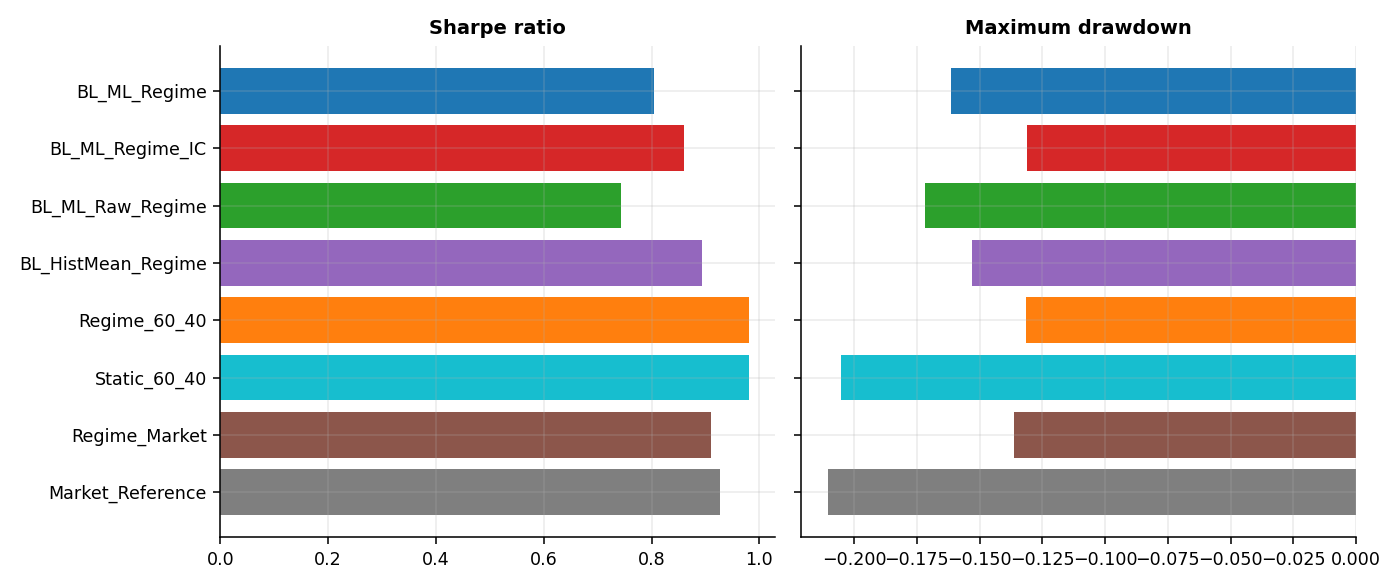

In [5]:
from IPython.display import Image
Image(str(P.figures / '14_overlay_ablation.png'))

In [6]:
pd.read_csv(P.tables / 'lstm_repair.csv')

,Asset,n_oos,Disp_raw,R2OOS_raw,IC_raw,Disp_fixed,R2OOS_fixed,IC_fixed
0,BTC-USD,83,0.908460,-1.143499,-0.152974,0.376352,-0.287887,-0.186642
1,DBC,187,1.571743,-2.558854,-0.019832,0.341697,-0.111408,-0.032128
2,EFA,211,2.057775,-3.441643,-0.021512,0.324490,-0.120353,-0.071426
3,ETH-USD,46,1.079048,-1.190229,0.251681,0.513431,-0.306366,0.211964
4,GLD,201,1.505301,-2.778237,-0.105604,0.279617,-0.059370,-0.023613
5,HYG,173,2.530111,-6.710572,-0.041341,0.445434,-0.246705,0.014984
6,IEF,211,2.641537,-6.946565,0.035431,0.272978,-0.116698,0.003390
7,SPY,211,2.087700,-3.750995,0.007026,0.307083,-0.134376,-0.131225
8,TLT,211,2.393833,-5.791665,0.034890,0.241544,-0.051528,0.054284


In [7]:
pd.read_csv(P.tables / 'skill_by_period.csv')

,Period,Forecast,MeanIC,MeanR2OOS,AssetsPositiveR2,Assets
0,full,xgb,-0.010116,-0.210809,0,9
1,full,rf,-0.010854,-0.115963,0,9
2,full,ridge,-0.081400,-0.057842,1,9
3,full,lstm,-0.017823,-0.159410,0,9
4,full,pooled_ridge,-0.059822,-0.065613,1,9
5,full,pooled_xgb,-0.051125,-0.093617,1,9
6,full,ensemble_equal,-0.013334,-0.063607,0,9
7,full,ensemble_stacked,-0.061495,-0.095870,0,9
8,full,stack_all,-0.090417,-0.053766,0,9
9,full,ensemble_final,-0.107198,-0.015755,0,9


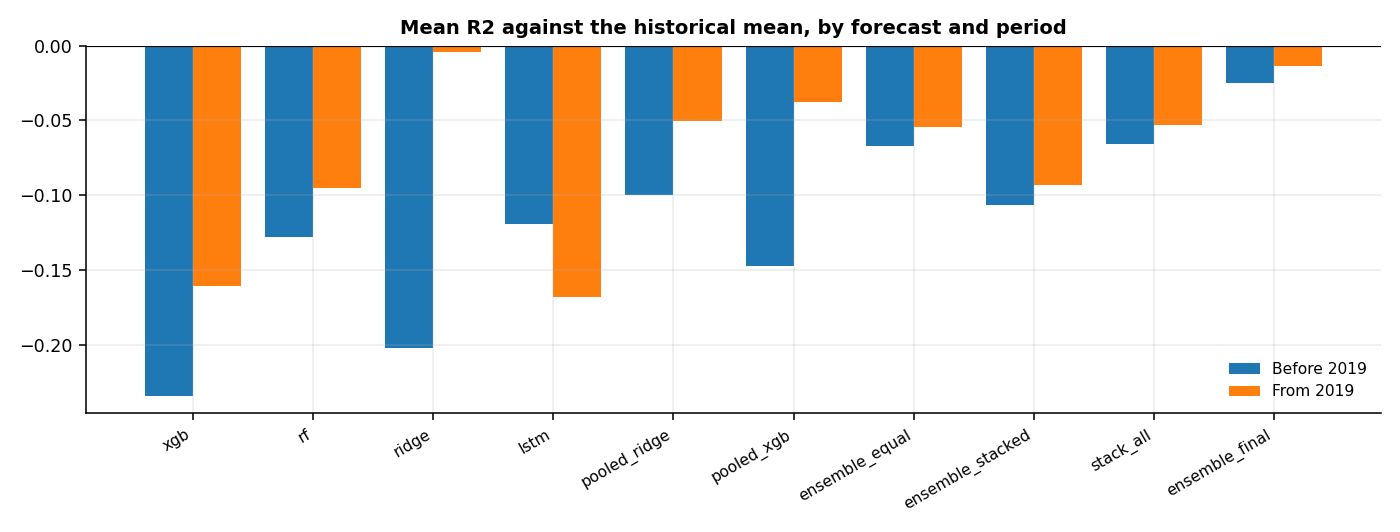

In [8]:
from IPython.display import Image
Image(str(P.figures / '15_forecast_repair.png'))

In [9]:
pd.read_csv(P.tables / 'period_split.csv')

,strategy,period,AnnReturn,AnnVol,Sharpe,MaxDrawdown,Months
0,BL_ML_Regime,development,0.059775,0.063721,0.885221,-0.089008,120
1,BL_ML_Regime,holdout,0.091869,0.087735,0.743030,-0.161379,91
2,BL_ML_Regime_IC,development,0.060328,0.060481,0.938019,-0.071528,120
3,BL_ML_Regime_IC,holdout,0.091558,0.081000,0.794257,-0.131160,91
4,BL_ML_NoRegime,development,0.073617,0.075602,0.929318,-0.083222,120
5,BL_ML_NoRegime,holdout,0.112440,0.113543,0.761115,-0.226850,91
6,BL_ML_Raw_Regime,development,0.060346,0.067014,0.852372,-0.077551,120
7,BL_ML_Raw_Regime,holdout,0.086311,0.092630,0.653814,-0.171596,91
8,BL_HistMean_Regime,development,0.066602,0.061802,1.015285,-0.065663,120
9,BL_HistMean_Regime,holdout,0.096971,0.087314,0.800458,-0.153128,91


In [10]:
pd.read_csv(P.tables / 'window_robustness.csv')

,Unnamed: 0,Sharpe_main,Sharpe_crisis_window,MaxDD_main,MaxDD_crisis_window,Months_main,Months_crisis_window
0,BL_ML_Regime,0.804914,0.691005,-0.161379,-0.171732,211.0,235.0
1,BL_ML_Regime_IC,0.859145,0.700122,-0.131160,-0.168795,211.0,235.0
2,BL_ML_NoRegime,0.825081,0.658259,-0.226850,-0.263664,211.0,235.0
3,BL_ML_Raw_Regime,0.743849,0.770263,-0.171596,-0.185326,211.0,235.0
4,BL_HistMean_Regime,0.893913,0.758701,-0.153128,-0.171732,211.0,235.0
5,Market_Reference,0.926883,0.688666,-0.210603,-0.314202,211.0,235.0
6,Equal_Weight,0.743854,0.695986,-0.235862,-0.286884,211.0,235.0
7,Static_60_40,0.980462,0.717282,-0.205222,-0.294934,211.0,235.0
8,Inverse_Vol,0.748663,0.671198,-0.177275,-0.184627,211.0,235.0
9,MeanVariance_LW,0.402221,0.390809,-0.369744,-0.469219,211.0,235.0


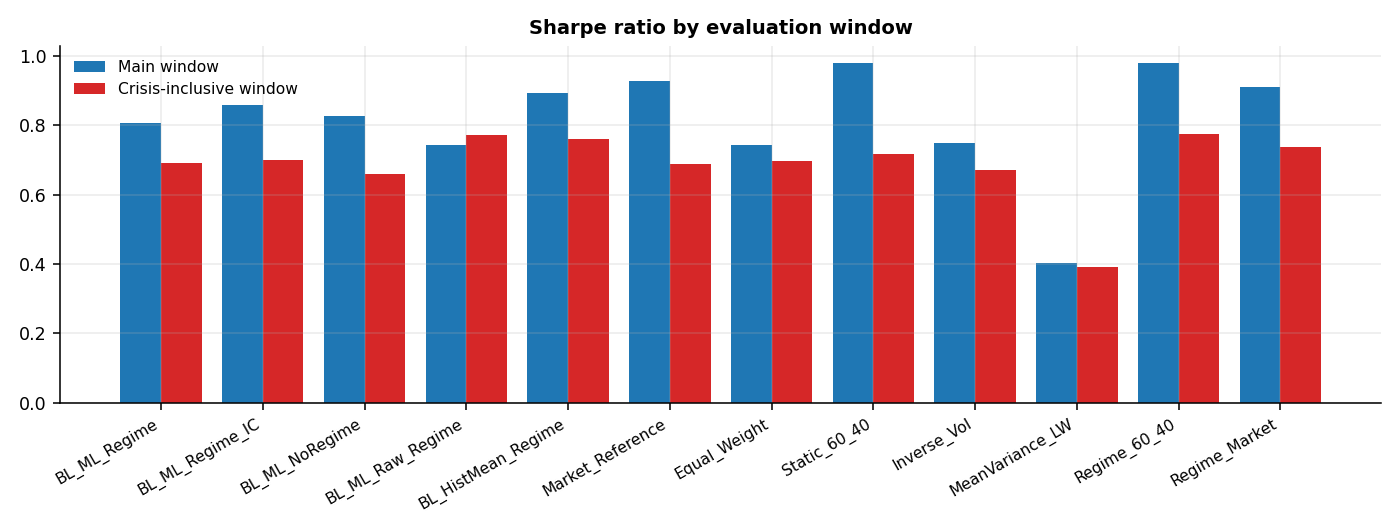

In [11]:
from IPython.display import Image
Image(str(P.figures / '16_window_robustness.png'))

In [12]:
pd.read_csv(P.tables / 'prior_comparison.csv')

,Prior,Variant,Sharpe,Sharpe_PriorPortfolio,Diff,CI_low,CI_high,p_value,MaxDrawdown,MaxDrawdown_PriorPortfolio
0,reference,BL_ML_Regime,0.804914,0.926883,-0.121969,-0.308700,0.040291,0.174956,-0.161379,-0.210603
1,reference,BL_ML_Regime_IC,0.859145,0.926883,-0.067738,-0.197103,0.046045,0.290927,-0.131160,-0.210603
2,reference,BL_HistMean_Regime,0.893913,0.926883,-0.032970,-0.194031,0.110077,0.677831,-0.153128,-0.210603
3,equal,BL_ML_Regime,0.589511,0.743854,-0.154342,-0.320431,-0.009953,0.053487,-0.176836,-0.235862
4,equal,BL_ML_Regime_IC,0.648097,0.743854,-0.095756,-0.224855,0.024850,0.137466,-0.153069,-0.235862
5,equal,BL_HistMean_Regime,0.651268,0.743854,-0.092585,-0.248634,0.051611,0.240690,-0.169302,-0.235862
6,inverse_vol,BL_ML_Regime,0.602127,0.750727,-0.148600,-0.364060,0.027378,0.141465,-0.142742,-0.174322
7,inverse_vol,BL_ML_Regime_IC,0.690727,0.750727,-0.059999,-0.201335,0.069198,0.403149,-0.110469,-0.174322
8,inverse_vol,BL_HistMean_Regime,0.693016,0.750727,-0.057711,-0.250055,0.103419,0.532117,-0.134237,-0.174322


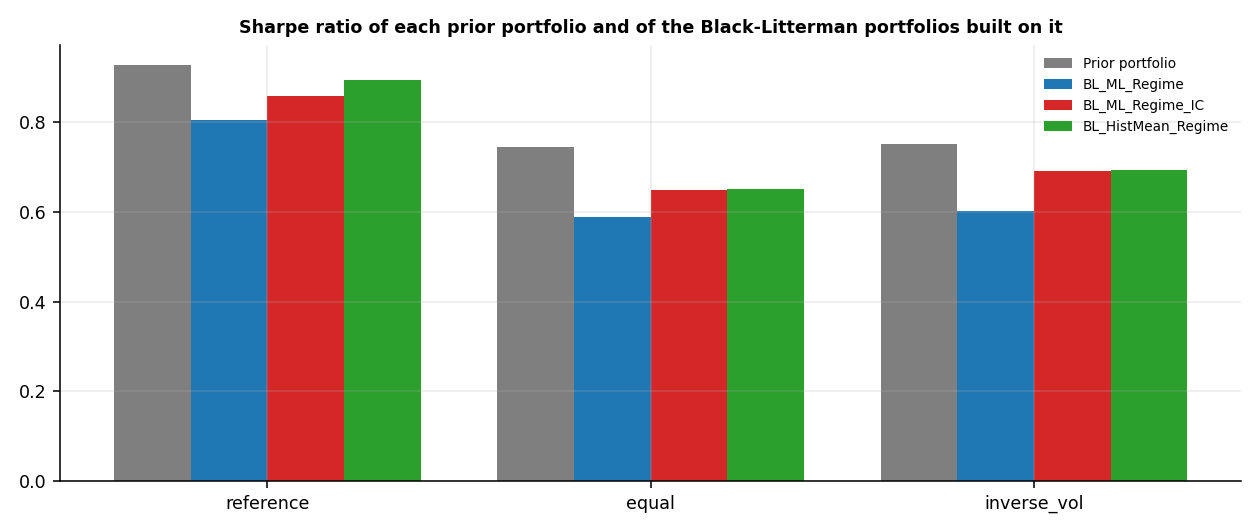

In [13]:
from IPython.display import Image
Image(str(P.figures / '17_prior_comparison.png'))

In [14]:
pd.read_csv(P.tables / 'holdout_status.csv')

,freeze_date,spec_hash,spec_unchanged,months_since_freeze,inference_possible
0,2026-07-31,7864aea1afd47cd0,True,0,False


In [15]:
pd.read_csv(P.tables / 'sensitivity.csv')

,Parameter,Value,IsDefault,Variant,Sharpe,AnnVol,MaxDrawdown,AnnTurnover,AvgCash,Sharpe_60_40
0,tau,0.025,False,BL_ML_Regime,0.840065,0.073461,-0.148613,1.704999,0.156393,0.980462
1,tau,0.025,False,BL_ML_Regime_IC,0.859056,0.071321,-0.132638,1.261591,0.173647,0.980462
2,tau,0.05,True,BL_ML_Regime,0.804914,0.074970,-0.161379,2.119617,0.162363,0.980462
3,tau,0.05,True,BL_ML_Regime_IC,0.859145,0.070029,-0.131160,1.323308,0.183717,0.980462
4,tau,0.1,False,BL_ML_Regime,0.743952,0.078616,-0.176257,2.661290,0.165218,0.980462
5,tau,0.1,False,BL_ML_Regime_IC,0.860961,0.067876,-0.128416,1.440668,0.202500,0.980462
6,tau,0.2,False,BL_ML_Regime,0.654823,0.084380,-0.190421,3.216250,0.162431,0.980462
7,tau,0.2,False,BL_ML_Regime_IC,0.852272,0.064785,-0.123639,1.596862,0.233886,0.980462
8,base_delta,1.5,False,BL_ML_Regime,0.736694,0.083157,-0.180925,2.731914,0.130370,0.980462
9,base_delta,1.5,False,BL_ML_Regime_IC,0.855087,0.070670,-0.133453,1.445027,0.171921,0.980462


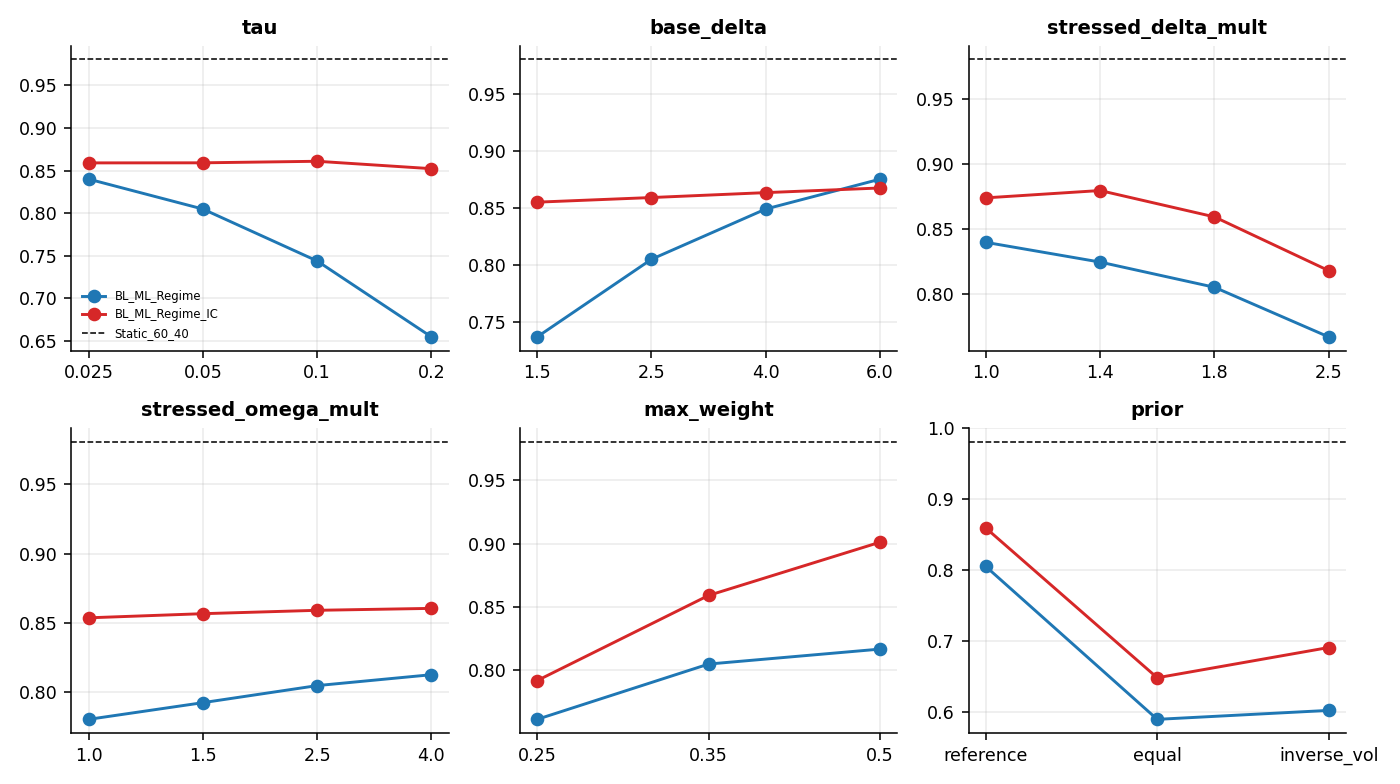

In [16]:
from IPython.display import Image
Image(str(P.figures / '13_sensitivity.png'))